In [13]:

import os
import io
from pathlib import Path

import cv2
import pandas as pd
import py7zr
from google.oauth2.credentials import Credentials
from google_auth_oauthlib.flow import InstalledAppFlow
from google.auth.transport.requests import Request
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

SCOPES = ['https://www.googleapis.com/auth/drive.readonly']
creds = None

if os.path.exists('token.json'):
    creds = Credentials.from_authorized_user_file('token.json', SCOPES)

if not creds or not creds.valid:
    if creds and creds.expired and creds.refresh_token:
        creds.refresh(Request())
    else:
        flow = InstalledAppFlow.from_client_secrets_file('credentials.json', SCOPES)
        creds = flow.run_local_server(port=0)
    with open('token.json', 'w') as token:
        token.write(creds.to_json())

service = build('drive', 'v3', credentials=creds)
print("Google Drive connected successfully!")

Google Drive connected successfully!


In [14]:
file_id = "1o8FfiIjvlbq7msw_Uga39zCX29OvMQxk"
file_name = "0001-0070_sample.7z"

download_folder = "sample_download"
extract_folder = os.path.join(download_folder, "extracted")
os.makedirs(download_folder, exist_ok=True)

file_path = os.path.join(download_folder, file_name)

# Download
if os.path.exists(file_path):
    print("File already exists!")
else:
    print("Starting download...")
    request = service.files().get_media(fileId=file_id)
    with io.FileIO(file_path, 'wb') as fh:
        downloader = MediaIoBaseDownload(fh, request, chunksize=10 * 1024 * 1024)
        done = False
        while not done:
            status, done = downloader.next_chunk()
            if status:
                print(f"Download Progress: {int(status.progress() * 100)}%")
    print("Download completed!")

print(f"File Size: {os.path.getsize(file_path) / (1024 * 1024):.2f} MB")

# Extract
if not os.path.exists(extract_folder):
    with py7zr.SevenZipFile(file_path, mode='r') as z:
        z.extractall(path=extract_folder)
    print("Extracted!")
else:
    print("Already extracted!")


for p in list(Path(extract_folder).iterdir())[:5]:
    print(p)

File already exists!
File Size: 132.79 MB
Already extracted!
sample_download\extracted\0001
sample_download\extracted\0002
sample_download\extracted\0003
sample_download\extracted\0004
sample_download\extracted\0005


In [15]:
DATASET_PATH = Path("sample_download/extracted") 
LABELS_PATH = Path("KARSL-502_Labels.xlsx")

labels = pd.read_excel(LABELS_PATH)
data = []

for folder in DATASET_PATH.iterdir():
    if folder.is_dir() and folder.name.isdigit():
        sign_id = int(folder.name)
        label = labels[labels["SignID"] == sign_id]
        if label.empty:
            continue

        arabic = label.iloc[0]["Sign-Arabic"]
        english = label.iloc[0]["Sign-English"]

        for video in folder.glob("*.mp4"):
            data.append({
                "Video_Path": str(video),
                "SignID": sign_id,
                "Arabic_Label": arabic,
                "English_Label": english
            })

df = pd.DataFrame(data)
df.to_csv("dataset_metadata.csv", index=False, encoding="utf-8-sig")

print("Dataset Metadata Created!")
print("Total Videos:", len(df))
print("Total Classes:", df["SignID"].nunique())
print("\nFirst 10 Rows:")
print(df.head(10).to_string(index=False))

# Class distribution
distribution = df.groupby(
    ["SignID", "Arabic_Label", "English_Label"]
).size().reset_index(name="Video_Count")

print("\nVideos per Class:")
print(distribution.to_string(index=False))

print("\nStatistics:")
print("Minimum:", distribution["Video_Count"].min())
print("Maximum:", distribution["Video_Count"].max())
print("Average:", distribution["Video_Count"].mean())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Metadata Created!
Total Videos: 560
Total Classes: 70

First 10 Rows:
                                                         Video_Path  SignID Arabic_Label English_Label
sample_download\extracted\0001\01_02_0001_(15_11_16_16_41_12)_c.mp4       1            0             0
sample_download\extracted\0001\01_02_0001_(15_11_16_16_41_48)_c.mp4       1            0             0
sample_download\extracted\0001\01_02_0001_(15_11_16_16_41_56)_c.mp4       1            0             0
sample_download\extracted\0001\01_02_0001_(16_11_16_15_50_08)_c.mp4       1            0             0
sample_download\extracted\0001\01_02_0001_(16_11_16_15_50_13)_c.mp4       1            0             0
sample_download\extracted\0001\01_02_0001_(16_11_16_15_50_24)_c.mp4       1            0             0
sample_download\extracted\0001\01_02_0001_(16_11_16_15_50_39)_c.mp4       1            0             0
sample_download\extracted\0001\01_02_0001_(16_11_16_15_50_51)_c.mp4       1            0          

In [16]:
df = pd.read_csv("dataset_metadata.csv")
video_info = []

for _, row in df.iterrows():
    cap = cv2.VideoCapture(row["Video_Path"])

    if not cap.isOpened():
        print("Cannot open:", row["Video_Path"])
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = frames / fps if fps > 0 else 0

    video_info.append({
        "Video_Path": row["Video_Path"],
        "SignID": row["SignID"],
        "FPS": fps,
        "Frame_Count": frames,
        "Width": width,
        "Height": height,
        "Duration": duration
    })
    cap.release()

result = pd.DataFrame(video_info)
result.to_csv("video_properties.csv", index=False, encoding="utf-8-sig")

print("\nVideo Analysis Completed!")
print("Total Videos:", len(result))
print("\nStatistics:")
print(result[["FPS", "Frame_Count", "Width", "Height", "Duration"]].describe())
print("\nResolutions:")
print(result.groupby(["Width", "Height"]).size())
print("\nFPS Values:")
print(result["FPS"].value_counts())


Video Analysis Completed!
Total Videos: 560

Statistics:
         FPS  Frame_Count   Width  Height    Duration
count  560.0   560.000000   560.0   560.0  560.000000
mean    30.0    16.612500  1920.0  1080.0    0.553750
std      0.0     4.743306     0.0     0.0    0.158110
min     30.0    11.000000  1920.0  1080.0    0.366667
25%     30.0    13.000000  1920.0  1080.0    0.433333
50%     30.0    15.000000  1920.0  1080.0    0.500000
75%     30.0    18.000000  1920.0  1080.0    0.600000
max     30.0    36.000000  1920.0  1080.0    1.200000

Resolutions:
Width  Height
1920   1080      560
dtype: int64

FPS Values:
FPS
30.0    560
Name: count, dtype: int64


In [17]:
df = pd.read_csv("dataset_metadata.csv")
df["Signer"] = df["Video_Path"].str.extract(r"\\(\d{2})_(\d{2})_\d{4}_")[0]
df["Session"] = df["Video_Path"].str.extract(r"\\(\d{2})_(\d{2})_\d{4}_")[1]
print(df.groupby(["Signer", "Session"]).size())

Signer  Session
01      02         248
02      02         312
dtype: int64


In [18]:
import numpy as np
from sklearn.model_selection import train_test_split


parts = [np.load(f"{n}.npz") for n in ["train", "val", "test"]]
X = np.concatenate([p["X"] for p in parts])   # (560, 16, 224, 224, 3)
y = np.concatenate([p["y"] for p in parts])   # (560,)
print("All:", X.shape, y.shape, "| classes:", len(np.unique(y)))

# 70% train / 15% val / 15% test (stratified)
idx = np.arange(len(y))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=42)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y[tmp_idx], random_state=42)

for name, ids in [("train", tr_idx), ("val", va_idx), ("test", te_idx)]:
    np.savez_compressed(f"{name}.npz", X=X[ids], y=y[ids])
    print(name, X[ids].shape, "| classes:", len(np.unique(y[ids])))

All: (560, 16, 224, 224, 3) (560,) | classes: 70
train (392, 16, 224, 224, 3) | classes: 70
val (84, 16, 224, 224, 3) | classes: 70
test (84, 16, 224, 224, 3) | classes: 70


In [19]:
import pandas as pd
import numpy as np
import cv2

df = pd.read_csv("dataset_metadata.csv")
vp = pd.read_csv("video_properties.csv")

print("=" * 40)
print("1) Missing values")
print(df.isnull().sum())

print("\n2) Duplicate paths:", df["Video_Path"].duplicated().sum())
df = df.drop_duplicates(subset="Video_Path").reset_index(drop=True)

print("\n3) Corrupted / empty videos")
bad = []
for p in df["Video_Path"]:
    cap = cv2.VideoCapture(p)
    ok, frame = cap.read()
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    if not ok or frame is None or n < 5:
        bad.append(p)
print("Bad videos:", len(bad))
df = df[~df["Video_Path"].isin(bad)].reset_index(drop=True)

print("\n4) Outliers (frame count)")
q1, q3 = vp["Frame_Count"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = vp[(vp["Frame_Count"] < low) | (vp["Frame_Count"] > high)]
print(f"Range: {low:.1f} - {high:.1f} | outliers: {len(out)}")


print("\n5) Fix labels")
num_words = {
    0: "صفر", 1: "واحد", 2: "اثنان", 3: "ثلاثة", 4: "أربعة", 5: "خمسة",
    6: "ستة", 7: "سبعة", 8: "ثمانية", 9: "تسعة", 10: "عشرة",
    20: "عشرون", 30: "ثلاثون", 40: "أربعون", 50: "خمسون", 60: "ستون",
    70: "سبعون", 80: "ثمانون", 90: "تسعون", 100: "مئة", 200: "مئتان",
    300: "ثلاثمئة", 400: "أربعمئة", 500: "خمسمئة", 600: "ستمئة",
    700: "سبعمئة", 800: "ثمانمئة", 900: "تسعمئة", 1000: "ألف",
    1000000: "مليون", 10000000: "عشرة ملايين",
}

def fix_label(row):
    if row["SignID"] <= 31:
        try:
            return num_words.get(int(row["Arabic_Label"]), row["Arabic_Label"])
        except (ValueError, TypeError):
            return row["Arabic_Label"]
    return row["Arabic_Label"]

df["Arabic_Label"] = df.apply(fix_label, axis=1)

print("\n6) Class check")
counts = df.groupby("SignID").size()
print("Classes:", df["SignID"].nunique(), "| min:", counts.min(), "| max:", counts.max())

df.to_csv("dataset_clean.csv", index=False, encoding="utf-8-sig")
print("\nSaved dataset_clean.csv | total videos:", len(df))
print(df[["SignID", "Arabic_Label", "English_Label"]].drop_duplicates().head(35).to_string(index=False))

1) Missing values
Video_Path       0
SignID           0
Arabic_Label     0
English_Label    0
dtype: int64

2) Duplicate paths: 0

3) Corrupted / empty videos
Bad videos: 0

4) Outliers (frame count)
Range: 5.5 - 25.5 | outliers: 43

5) Fix labels

6) Class check
Classes: 70 | min: 7 | max: 9

Saved dataset_clean.csv | total videos: 560
 SignID Arabic_Label English_Label
      1          صفر             0
      2         واحد             1
      3        اثنان             2
      4        ثلاثة             3
      5        أربعة             4
      6         خمسة             5
      7          ستة             6
      8         سبعة             7
      9       ثمانية             8
     10         تسعة             9
     11         عشرة            10
     12        عشرون            20
     13       ثلاثون            30
     14       أربعون            40
     15        خمسون            50
     16         ستون            60
     17        سبعون            70
     18       ثمانون           

In [26]:
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

def crop(f):
    h, w = f.shape[:2]
    s = int(0.85 * h)
    x0 = (w - s) // 2
    return f[h - s:h, x0:x0 + s]

df = pd.read_csv("dataset_clean.csv", encoding="utf-8-sig")
df = df.sort_values("Video_Path").reset_index(drop=True)

T = 16
X = np.zeros((len(df), T, 224, 224, 3), dtype=np.uint8)

for i, p in enumerate(df["Video_Path"]):
    cap = cv2.VideoCapture(p)
    frames = []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        f = cv2.resize(crop(f), (224, 224))
        frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    cap.release()
    if not frames:
        raise ValueError(f"No frames: {p}")
    idx = np.linspace(0, len(frames) - 1, T).round().astype(int)
    X[i] = np.stack([frames[j] for j in idx])

y = df["SignID"].values - 1          # 0..69
paths = df["Video_Path"].values.astype(str)

ids = np.arange(len(y))
tr, tmp = train_test_split(ids, test_size=0.30, stratify=y, random_state=42)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=42)

for name, s in [("train", tr), ("val", va), ("test", te)]:
    np.savez_compressed(f"{name}.npz", X=X[s], y=y[s], paths=paths[s])
    print(name, X[s].shape, "| classes:", len(np.unique(y[s])))

train (392, 16, 224, 224, 3) | classes: 70
val (84, 16, 224, 224, 3) | classes: 70
test (84, 16, 224, 224, 3) | classes: 70


In [21]:
df = pd.read_csv("dataset_clean.csv", encoding="utf-8-sig")
df["Signer"] = df["Video_Path"].str.extract(r"\\(\d{2})_\d{2}_\d{4}_")[0]
print(pd.crosstab(df["Signer"], df["SignID"] <= 31))

ts = df["Video_Path"].str.extract(r"\((\d{2})_(\d{2})_(\d{2})_(\d{2})_(\d{2})_(\d{2})\)")
df["RecordDate"] = ts[0] + "-" + ts[1] + "-" + ts[2]
print("Unmatched:", df["RecordDate"].isna().sum())
t = df.groupby(["SignID", "RecordDate"]).size().unstack(fill_value=0)
print((t > 0).sum(axis=1).value_counts())
print((df["Frame_Count"] if "Frame_Count" in df else pd.read_csv("video_properties.csv")["Frame_Count"]).lt(16).mean())

SignID  False  True 
Signer              
01          0    248
02        312      0
Unmatched: 0
2    70
Name: count, dtype: int64
0.5589285714285714


In [27]:
import numpy as np
import pandas as pd

meta = pd.DataFrame({"path": paths, "y": y})
ts = meta["path"].str.extract(r"\((\d{2})_(\d{2})_(\d{2})_")
meta["date"] = ts[0] + "-" + ts[1] + "-" + ts[2]

rng = np.random.default_rng(42)
tr, va, te = [], [], []

for c, g in meta.groupby("y"):
    dates = g["date"].value_counts().index
    main = rng.permutation(g.index[g["date"] == dates[0]].to_numpy())
    other = g.index[g["date"] == dates[1]].to_numpy()
    va.append(main[0])
    tr.extend(main[1:])
    te.extend(other)

tr, va, te = np.array(tr), np.array(va), np.array(te)

# تأكيد: مفيش class ليها نفس اليوم في train/val و test
def used(s):
    return set(zip(meta["y"].iloc[s], meta["date"].iloc[s]))
assert not (used(np.r_[tr, va]) & used(te))

for name, s in [("train", tr), ("val", va), ("test", te)]:
    np.savez_compressed(f"{name}_date.npz", X=X[s], y=y[s], paths=paths[s])
    n = np.bincount(y[s], minlength=70)
    print(name, len(s), "| classes:", (n > 0).sum(), "| per class:", n.min(), "-", n.max())

train 285 | classes: 70 | per class: 3 - 6
val 70 | classes: 70 | per class: 1 - 1
test 205 | classes: 70 | per class: 1 - 4


In [23]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 324.9 kB/s eta 0:00:28
   -- ------------------------------------- 0.5/9.5 MB 324.9 kB/s eta 0:00:28
   -- ------------------------------------- 0.5/9.5 MB 324.9 kB/s eta 0:00:28
   -- ------------------------------------- 0.5/9.5 MB 324.9 kB/s eta 0:00:28
   

Matplotlib is building the font cache; this may take a moment.


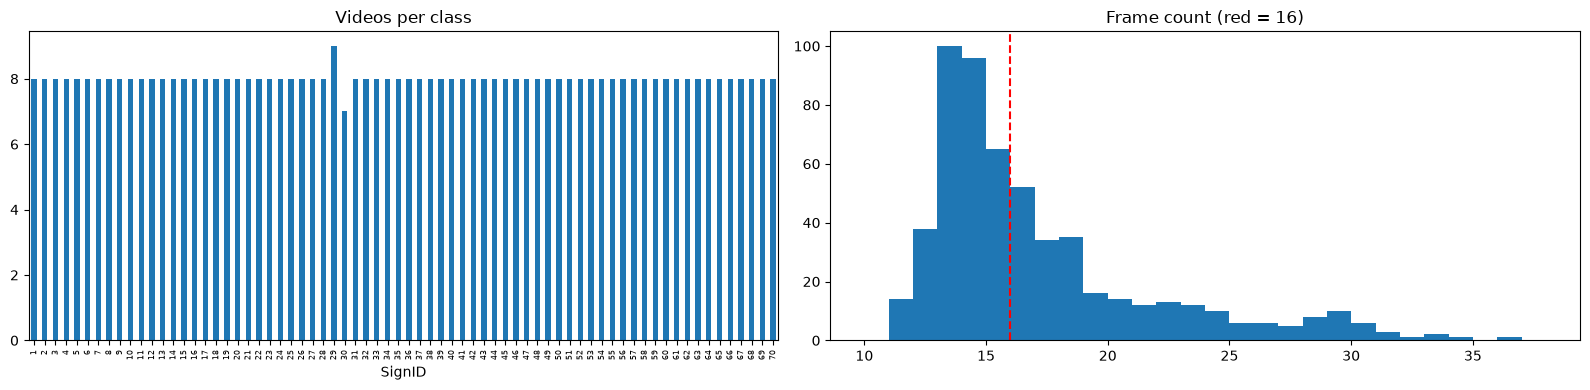

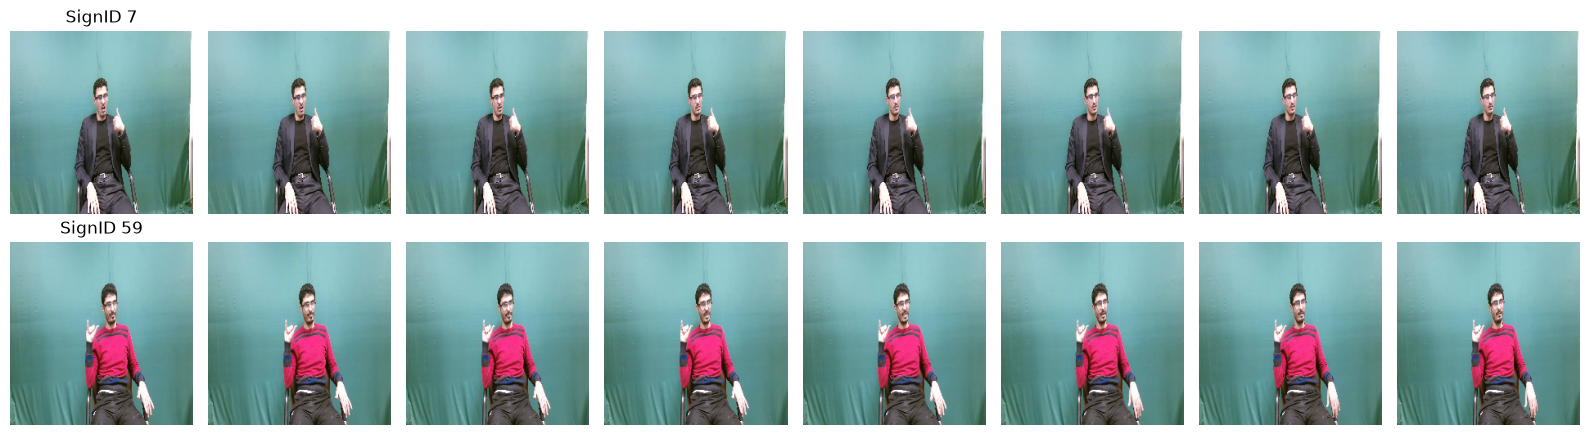

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dataset_clean.csv", encoding="utf-8-sig")
vp = pd.read_csv("video_properties.csv")


fig, ax = plt.subplots(1, 2, figsize=(16, 4))
df["SignID"].value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Videos per class")
ax[0].tick_params(axis="x", labelsize=6)
ax[1].hist(vp["Frame_Count"], bins=range(10, 39))
ax[1].axvline(16, color="red", linestyle="--")
ax[1].set_title("Frame count (red = 16)")
plt.tight_layout()
plt.show()


d = np.load("train.npz")
Xs, ys = d["X"], d["y"]
ids = [np.where(ys < 31)[0][0], np.where(ys >= 31)[0][0]]

fig, ax = plt.subplots(2, 8, figsize=(16, 4.5))
for r, i in enumerate(ids):
    for c, t in enumerate(range(0, 16, 2)):
        ax[r, c].imshow(Xs[i, t])
        ax[r, c].axis("off")
    ax[r, 0].set_title(f"SignID {ys[i] + 1}")
plt.tight_layout()
plt.show()

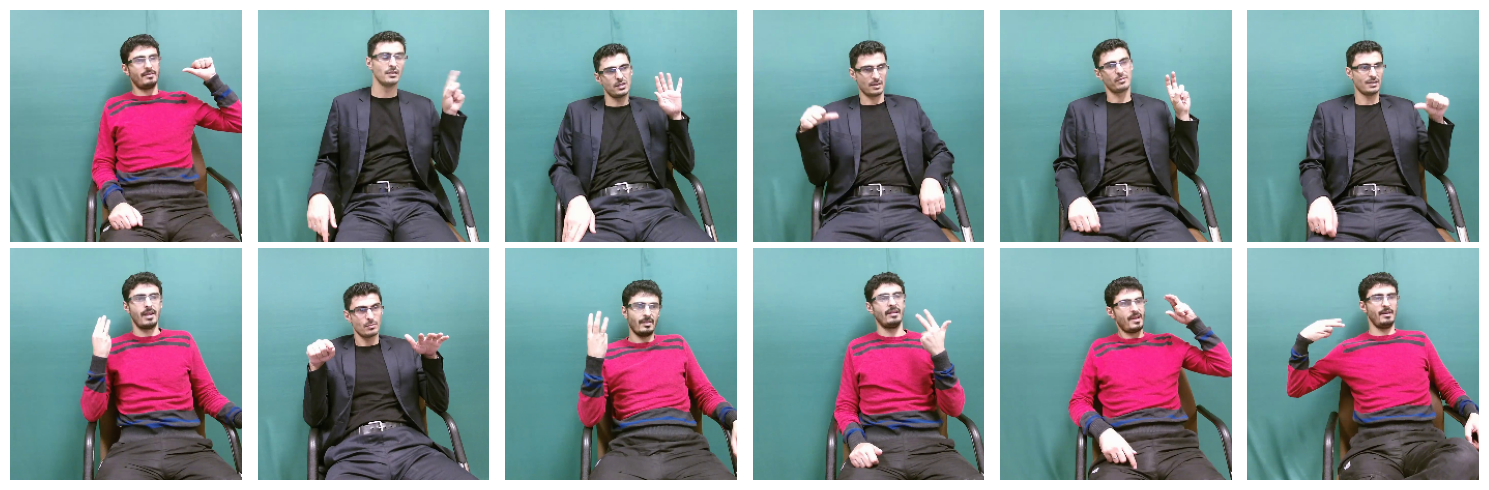

In [25]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt

def crop(f):
    h, w = f.shape[:2]
    s = int(0.85 * h)
    x0 = (w - s) // 2
    return f[h - s:h, x0:x0 + s]

df = pd.read_csv("dataset_clean.csv", encoding="utf-8-sig")
sample = df.sample(12, random_state=1)

fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for a, p in zip(ax.ravel(), sample["Video_Path"]):
    cap = cv2.VideoCapture(p)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2)
    ok, f = cap.read()
    cap.release()
    if ok:
        f = cv2.resize(crop(f), (224, 224))
        a.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    a.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
!pip install -q mediapipe==0.10.14 tqdm